# 07 — SVM Classification: Demand Level

**Member 4 — SVM & Optimization | NYC Yellow Taxi 2026**

Notebook ini disesuaikan dengan schema aktual dari `script/05_features.ipynb`.

## Tujuan
Klasifikasi `demand_level` untuk setiap zona-jam menjadi **Rendah, Sedang, Tinggi** menggunakan:
- Linear SVM (`LinearSVC`)
- RBF SVM (`SVC`)

## Data & split
- File: `datasets/interim/2026/features_dataset.parquet`
- Train: Januari–April (`split == "train"`)
- Validation: Mei (`split == "validation"`)
- Test: Juni (`split == "test"`), hanya untuk evaluasi akhir setelah model dipilih.

Target kelas dibuat oleh notebook feature engineering menggunakan tercile (1/3 dan 2/3 quantile) dari `target_pickup_count` pada Train saja.

**Test set tidak digunakan untuk fitting, tuning, atau pemilihan model.**


**Dokumentasi:** Memuat library yang dibutuhkan, metrik evaluasi, pipeline preprocessing/model, serta konfigurasi target, label kelas, fitur, dan random seed. `StandardScaler` akan dipasang di dalam pipeline agar scaler hanya belajar dari data training.


In [1]:
# 1. Imports & configuration
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TARGET = "demand_level"
LABELS = ["Rendah", "Sedang", "Tinggi"]

FEATURES = [
    "hour_of_day",
    "day_of_week",
    "month",
    "is_weekend",
    "is_holiday",
    "is_major_nyc_event",
    "PU_longitude",
    "PU_latitude",
    "is_airport",
    "is_cbd",
    "lag_1",
    "lag_24",
    "lag_168",
    "roll_24",
    "roll_168"
]

TARGET = "demand_level"
SPLIT_COL = "split"

TRAIN_LABEL = "train"
VALIDATION_LABEL = "validation"
TEST_LABEL = "test"

print("Configuration ready.")


Configuration ready.


## 2. Load feature dataset

Try common working-directory locations. If none exists, set `DATA_PATH` manually. This file is created by running `script/05_features.ipynb`.

**Dokumentasi:** Membaca dataset fitur hasil feature engineering. Path dicari dari beberapa kemungkinan working directory agar notebook tetap bisa dijalankan dari root project maupun folder `script`.


In [2]:
candidate_paths = [
    Path("datasets/interim/2026/features_dataset.parquet"),
    Path("../datasets/interim/2026/features_dataset.parquet"),
    Path("../../datasets/interim/2026/features_dataset.parquet"),
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), candidate_paths[0])
print("Using:", DATA_PATH.resolve())

if DATA_PATH.exists():
    data = pd.read_parquet(DATA_PATH)
    print("Shape:", data.shape)
    display(data.head())
else:
    print("Feature dataset not found. Run 05_features.ipynb first.")


Using: C:\IF SEM 5\Data Science Teori\Cooked-DS-Final-Project\datasets\interim\2026\features_dataset.parquet
Shape: (1053841, 22)


,hour,zone_id,PU_longitude,PU_latitude,PU_zone_name,PU_borough,is_airport,is_cbd,hour_of_day,day_of_week,...,is_holiday,is_major_nyc_event,lag_1,lag_24,lag_168,roll_24,roll_168,target_pickup_count,demand_level,split
0,2026-01-08 00:00:00,1,-74.174,40.691831,Newark Airport,EWR,1,0,0,3,...,0,0,0.0,0.0,0.0,0.25,1.083333,0.0,Rendah,train
1,2026-01-08 01:00:00,1,-74.174,40.691831,Newark Airport,EWR,1,0,1,3,...,0,0,0.0,0.0,0.0,0.25,1.083333,0.0,Rendah,train
2,2026-01-08 02:00:00,1,-74.174,40.691831,Newark Airport,EWR,1,0,2,3,...,0,0,0.0,0.0,1.0,0.25,1.083333,0.0,Rendah,train
3,2026-01-08 03:00:00,1,-74.174,40.691831,Newark Airport,EWR,1,0,3,3,...,0,0,0.0,0.0,0.0,0.25,1.077381,0.0,Rendah,train
4,2026-01-08 04:00:00,1,-74.174,40.691831,Newark Airport,EWR,1,0,4,3,...,0,0,0.0,0.0,3.0,0.25,1.077381,0.0,Rendah,train


**Dokumentasi:** Memeriksa apakah seluruh predictor, target, dan kolom split tersedia. Setelah validasi, data dipisahkan berdasarkan split yang telah ditetapkan tim. Test disimpan dan tidak digunakan dalam pemilihan model.


In [3]:
# 3. Validate schema and split data
required = FEATURES + [TARGET, "split"]
if "data" in globals():
    missing = [c for c in required if c not in data.columns]
    if missing:
        raise ValueError(f"Required columns missing from feature dataset: {missing}")
    print("Columns validated.")

    train_df = data[data["split"] == "train"].copy()
    val_df = data[data["split"] == "validation"].copy()
    test_df = data[data["split"] == "test"].copy()

    print(f"Train: {train_df.shape}")
    print(f"Validation: {val_df.shape}")
    print(f"Test (reserved): {test_df.shape}")
    print("\\nTrain label distribution:")
    display(train_df[TARGET].value_counts())
    display(train_df[TARGET].value_counts(normalize=True).round(3))


Columns validated.
Train: (668809, 22)
Validation: (195672, 22)
Test (reserved): (189360, 22)
\nTrain label distribution:


demand_level
Rendah    253530
Tinggi    208014
Sedang    207265
Name: count, dtype: int64

demand_level
Rendah    0.379
Tinggi    0.311
Sedang    0.310
Name: proportion, dtype: float64

## 4. Prepare features and target

Only the 14 features specified in the feature-engineering notebook are used. Excluded columns include timestamps, zone identifiers/names, the numeric regression target, and split metadata.

**Dokumentasi:** Memisahkan predictor (`X`) dan label (`y`) untuk Train dan Validation. Pemeriksaan label dan missing values mencegah model dilatih dengan schema yang tidak sesuai.


In [4]:
if "train_df" in globals():
    X_train_full = train_df[FEATURES].copy()
    y_train_full = train_df[TARGET].astype(str).copy()

    X_val = val_df[FEATURES].copy()
    y_val = val_df[TARGET].astype(str).copy()

    # Confirm class labels
    print("Train labels:", sorted(y_train_full.unique()))
    print("Validation labels:", sorted(y_val.unique()))
    assert set(y_train_full.unique()).issubset(set(LABELS)), "Unexpected demand_level labels"
    assert not X_train_full.isna().any().any(), "Missing values in train features"
    assert not X_val.isna().any().any(), "Missing values in validation features"


Train labels: ['Rendah', 'Sedang', 'Tinggi']
Validation labels: ['Rendah', 'Sedang', 'Tinggi']


## 5. Sampling for computational feasibility

Linear SVM can be trained on a larger sample. RBF SVM is more computationally expensive, so its sample cap is smaller. Sampling is done **inside Train only** and stratified by class to retain class proportions. Validation remains complete and untouched.

**Dokumentasi:** Mengambil sampel stratified dari Train saja. Proporsi kelas dipertahankan dan Validation tidak disentuh. Batas sampel mengurangi biaya komputasi, terutama untuk RBF SVM.


In [5]:
MAX_LINEAR_ROWS = 150_000
MAX_RBF_ROWS = 30_000

def stratified_train_sample(X, y, max_rows, seed=RANDOM_STATE):
    if max_rows is None or len(X) <= max_rows:
        return X, y
    Xs, _, ys, _ = train_test_split(
        X, y, train_size=max_rows, random_state=seed, stratify=y
    )
    return Xs, ys

if "X_train_full" in globals():
    X_linear, y_linear = stratified_train_sample(
        X_train_full, y_train_full, MAX_LINEAR_ROWS
    )
    X_rbf, y_rbf = stratified_train_sample(
        X_train_full, y_train_full, MAX_RBF_ROWS
    )
    print("Linear training sample:", len(X_linear))
    print("RBF training sample:", len(X_rbf))
    print("Validation rows (full):", len(X_val))


Linear training sample: 150000
RBF training sample: 30000
Validation rows (full): 195672


## 6. Evaluation function

Scaling is fit only on the training sample because `StandardScaler` is inside the Pipeline. Macro-averaged precision, recall, and F1 treat all three classes equally.

**Dokumentasi:** Fungsi helper untuk melatih model, mencatat waktu training/prediksi, menghasilkan prediksi Validation, serta menghitung accuracy, macro precision, macro recall, dan macro F1.


In [6]:
def fit_evaluate(name, estimator, Xtr, ytr, Xva, yva):
    start = time.perf_counter()
    estimator.fit(Xtr, ytr)
    train_time = time.perf_counter() - start

    start = time.perf_counter()
    predictions = estimator.predict(Xva)
    predict_time = time.perf_counter() - start

    metric_row = {
        "model": name,
        "accuracy": accuracy_score(yva, predictions),
        "precision_macro": precision_score(yva, predictions, average="macro", zero_division=0),
        "recall_macro": recall_score(yva, predictions, average="macro", zero_division=0),
        "f1_macro": f1_score(yva, predictions, average="macro", zero_division=0),
        "train_seconds": train_time,
        "predict_seconds": predict_time,
        "n_train": len(Xtr),
        "n_validation": len(Xva)
    }
    return metric_row, predictions, estimator


## 7. Linear SVM

**Dokumentasi:** Melatih Linear SVM pada sampel Train dan mengevaluasi pada Validation. Model Linear menjadi eksperimen utama karena lebih efisien untuk data besar.


In [7]:
linear_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LinearSVC(class_weight="balanced", random_state=RANDOM_STATE))
])

linear_metrics, linear_pred, linear_model = fit_evaluate(
    "Linear SVM", linear_svm, X_linear, y_linear, X_val, y_val
)
print(linear_metrics)
print(classification_report(y_val, linear_pred, labels=LABELS, zero_division=0))


{'model': 'Linear SVM', 'accuracy': 0.7395283944560285, 'precision_macro': 0.7328735246723123, 'recall_macro': 0.723407751720675, 'f1_macro': 0.7193414702374675, 'train_seconds': 7.883676400000695, 'predict_seconds': 0.05261579999933019, 'n_train': 150000, 'n_validation': 195672}
              precision    recall  f1-score   support

      Rendah       0.70      0.87      0.77     76650
      Sedang       0.61      0.42      0.50     57983
      Tinggi       0.89      0.88      0.89     61039

    accuracy                           0.74    195672
   macro avg       0.73      0.72      0.72    195672
weighted avg       0.73      0.74      0.73    195672



**Dokumentasi:** Menampilkan confusion matrix Linear SVM pada Validation. Baris adalah label aktual dan kolom adalah prediksi; gunakan untuk melihat kelas yang sering salah dikenali.


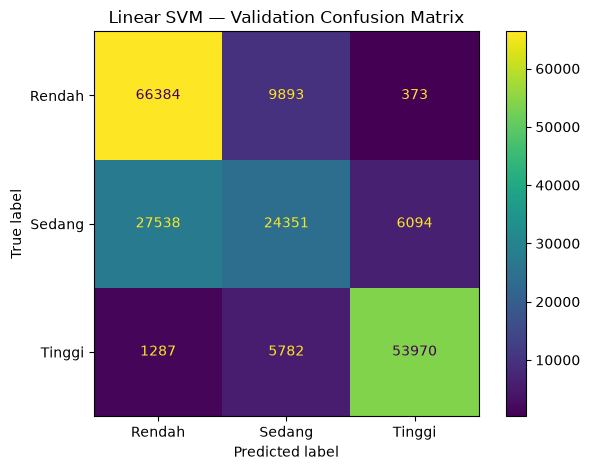

In [8]:
# Linear SVM validation confusion matrix
cm_linear = confusion_matrix(y_val, linear_pred, labels=LABELS)
disp = ConfusionMatrixDisplay(cm_linear, display_labels=LABELS)
disp.plot(values_format="d")
plt.title("Linear SVM — Validation Confusion Matrix")
plt.tight_layout()
plt.show()


## 8. RBF SVM

RBF kernel can model non-linear relationships but has greater training cost. Training uses the capped Train-only sample; validation is kept complete.

**Dokumentasi:** Melatih RBF SVM pada sampel Train dan menguji prediksi pada Validation. Kernel RBF lebih mahal secara komputasi; bila terlalu lama, hentikan cell dan gunakan workflow RBF ringan pada bagian tambahan di akhir notebook.


In [9]:
rbf_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced"
    ))
])

rbf_metrics, rbf_pred, rbf_model = fit_evaluate(
    "RBF SVM", rbf_svm, X_rbf, y_rbf, X_val, y_val
)
print(rbf_metrics)
print(classification_report(y_val, rbf_pred, labels=LABELS, zero_division=0))


{'model': 'RBF SVM', 'accuracy': 0.7557085326464696, 'precision_macro': 0.7643544002119157, 'recall_macro': 0.7550479694706529, 'f1_macro': 0.7579625974655135, 'train_seconds': 32.980892399995355, 'predict_seconds': 364.0030268999981, 'n_train': 30000, 'n_validation': 195672}
              precision    recall  f1-score   support

      Rendah       0.78      0.75      0.76     76650
      Sedang       0.58      0.67      0.62     57983
      Tinggi       0.93      0.85      0.89     61039

    accuracy                           0.76    195672
   macro avg       0.76      0.76      0.76    195672
weighted avg       0.77      0.76      0.76    195672



**Dokumentasi:** Menampilkan confusion matrix RBF SVM pada Validation untuk mengidentifikasi pola kesalahan per kelas.


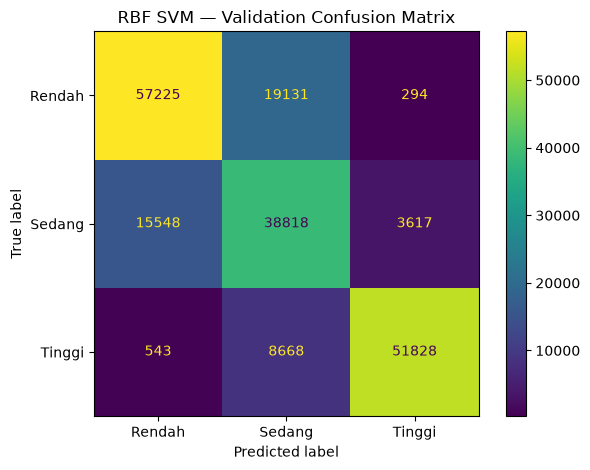

In [10]:
# RBF SVM validation confusion matrix
cm_rbf = confusion_matrix(y_val, rbf_pred, labels=LABELS)
disp = ConfusionMatrixDisplay(cm_rbf, display_labels=LABELS)
disp.plot(values_format="d")
plt.title("RBF SVM — Validation Confusion Matrix")
plt.tight_layout()
plt.show()


## 9. Compare & export metrics

Metrics shown are **Validation (May)** results only. The Test split (June) remains reserved for final evaluation.

**Dokumentasi:** Menggabungkan metrik Validation dari model yang telah selesai dijalankan dan menyimpan tabel ke folder `out`. Jalankan hanya jika kedua variabel metrics tersedia; workflow tambahan di akhir menyediakan export yang lebih fleksibel.


In [11]:
metrics_df = pd.DataFrame([linear_metrics, rbf_metrics]).sort_values(
    "f1_macro", ascending=False
)
display(metrics_df)

output_candidates = [Path("out"), Path("../out"), Path("../../out")]
OUT_DIR = next((p for p in output_candidates if p.exists()), output_candidates[0])
OUT_DIR.mkdir(exist_ok=True, parents=True)
metrics_df.to_csv(OUT_DIR / "svm_validation_metrics.csv", index=False)
print("Metrics saved to:", (OUT_DIR / "svm_validation_metrics.csv").resolve())


,model,accuracy,precision_macro,recall_macro,f1_macro,train_seconds,predict_seconds,n_train,n_validation
1,RBF SVM,0.755709,0.764354,0.755048,0.757963,32.980892,364.003027,30000,195672
0,Linear SVM,0.739528,0.732874,0.723408,0.719341,7.883676,0.052616,150000,195672


Metrics saved to: C:\IF SEM 5\Data Science Teori\Cooked-DS-Final-Project\out\svm_validation_metrics.csv


## 10. Discussion template

Complete this after running the models:

- Which model achieved the better macro-F1 on Validation?
- Which demand class is most frequently confused? Use the confusion matrices.
- Does the model identify **Tinggi** demand adequately (recall for high-demand zones)?
- How much training time does RBF require compared with Linear SVM?
- What are the limitations of capped training samples?
- Confirm that test data was not used for model selection.

**Do not report metrics until the notebook has successfully run with the team's feature dataset.**


**Dokumentasi:** Konfigurasi fitur predictor dan target sesuai schema aktual dataset. Jangan memasukkan metadata split atau target numerik ke predictor.


In [12]:
FEATURES = [
    "hour_of_day",
    "day_of_week",
    "month",
    "is_weekend",
    "is_holiday",
    "is_major_nyc_event",
    "PU_longitude",
    "PU_latitude",
    "is_airport",
    "is_cbd",
    "lag_1",
    "lag_24",
    "lag_168",
    "roll_24",
    "roll_168"
]

TARGET = "demand_level"
SPLIT_COL = "split"

**Dokumentasi:** Memuat dataset dari lokasi project yang benar (relatif terhadap notebook di folder `script`) dan memvalidasi kolom yang diperlukan.


In [13]:
import pandas as pd
import numpy as np

DATA_PATH = "../datasets/interim/2026/features_dataset.parquet"

df = pd.read_parquet(DATA_PATH)

print("Dataset:", df.shape)

# Pastikan semua fitur tersedia
missing_features = [f for f in FEATURES if f not in df.columns]

if missing_features:
    raise ValueError(f"Missing features: {missing_features}")

# Pastikan target dan split tersedia
assert TARGET in df.columns
assert SPLIT_COL in df.columns

print("All required features are available!")

Dataset: (1053841, 22)
All required features are available!


**Dokumentasi:** Membentuk subset Train dan Validation berdasarkan kolom `split` serta menampilkan distribusi target untuk memeriksa keseimbangan kelas.


In [14]:
# Split berdasarkan kolom split yang sudah disediakan
train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "validation"].copy()

print("Train size:", train_df.shape)
print("Validation size:", val_df.shape)

print("\nTrain target distribution:")
print(train_df[TARGET].value_counts())

print("\nValidation target distribution:")
print(val_df[TARGET].value_counts())

Train size: (668809, 22)
Validation size: (195672, 22)

Train target distribution:
demand_level
Rendah    253530
Tinggi    208014
Sedang    207265
Name: count, dtype: int64

Validation target distribution:
demand_level
Rendah    76650
Tinggi    61039
Sedang    57983
Name: count, dtype: int64


**Dokumentasi:** Cell sampling tambahan lama. Cell ini menggunakan `groupby().apply()` dan tidak perlu dijalankan; gunakan bagian workflow aman yang ditambahkan di akhir notebook untuk menghindari masalah kolom target dan duplikasi workflow.


In [19]:
linear_parts = []
rbf_parts = []

for label in train_df[TARGET].unique():
    group = train_df[train_df[TARGET] == label]

    linear_parts.append(
        group.sample(n=min(len(group), 50000), random_state=42)
    )

    rbf_parts.append(
        group.sample(n=min(len(group), 5000), random_state=42)
    )

linear_train = pd.concat(linear_parts, ignore_index=True)
rbf_train = pd.concat(rbf_parts, ignore_index=True)

print("Linear SVM sample:", linear_train.shape)
print("RBF SVM sample:", rbf_train.shape)
print("\nTarget distribution:")
print(linear_train[TARGET].value_counts())

Linear SVM sample: (150000, 22)
RBF SVM sample: (15000, 22)

Target distribution:
demand_level
Rendah    50000
Sedang    50000
Tinggi    50000
Name: count, dtype: int64


**Dokumentasi:** Cell training Linear tambahan lama. Jangan jalankan cell ini; gunakan workflow final yang ditambahkan di akhir notebook agar preprocessing, sampling, dan evaluasi tersusun konsisten.


In [18]:
print("TARGET =", TARGET)
print("linear_train shape =", linear_train.shape)
print("linear_train columns =")
print(linear_train.columns.tolist())

print("\nTarget exists in linear_train:",
      TARGET in linear_train.columns)

TARGET = demand_level
linear_train shape = (150000, 21)
linear_train columns =
['hour', 'zone_id', 'PU_longitude', 'PU_latitude', 'PU_zone_name', 'PU_borough', 'is_airport', 'is_cbd', 'hour_of_day', 'day_of_week', 'month', 'is_weekend', 'is_holiday', 'is_major_nyc_event', 'lag_1', 'lag_24', 'lag_168', 'roll_24', 'roll_168', 'target_pickup_count', 'split']

Target exists in linear_train: False


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import time

# Ambil predictor dan target saja
X_train_linear = linear_train[FEATURES]
y_train_linear = linear_train[TARGET]

X_val = val_df[FEATURES]
y_val = val_df[TARGET]

# Pipeline preprocessing + model
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

# Training
start_train = time.time()

linear_model.fit(X_train_linear, y_train_linear)

linear_train_time = time.time() - start_train

print(f"Linear SVM training completed!")
print(f"Training time: {linear_train_time:.2f} seconds")

Linear SVM training completed!
Training time: 3.13 seconds


In [22]:
# Evaluasi Linear SVM pada Validation Set

start_eval = time.time()

y_pred_linear = linear_model.predict(X_val)

linear_eval_time = time.time() - start_eval

print("Linear SVM Validation Results")
print("=" * 40)

print("Accuracy:", accuracy_score(y_val, y_pred_linear))
print("Precision (macro):", precision_score(y_val, y_pred_linear, average="macro"))
print("Recall (macro):", recall_score(y_val, y_pred_linear, average="macro"))
print("F1-score (macro):", f1_score(y_val, y_pred_linear, average="macro"))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_linear))

print("Evaluation time:", round(linear_eval_time, 2), "seconds")

Linear SVM Validation Results
Accuracy: 0.7370446461425242
Precision (macro): 0.7316237385280139
Recall (macro): 0.7268804850060867
F1-score (macro): 0.7271028331969811

Classification Report:
              precision    recall  f1-score   support

      Rendah       0.71      0.81      0.76     76650
      Sedang       0.58      0.49      0.53     57983
      Tinggi       0.90      0.88      0.89     61039

    accuracy                           0.74    195672
   macro avg       0.73      0.73      0.73    195672
weighted avg       0.73      0.74      0.73    195672

Evaluation time: 0.07 seconds


# CELL RBF - Training & Validation

In [23]:
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import time


X_train_rbf = rbf_train[FEATURES]
y_train_rbf = rbf_train[TARGET]

# Ambil subset validation agar RBF tidak terlalu berat
X_val_rbf, _, y_val_rbf, _ = train_test_split(
    X_val,
    y_val,
    train_size=30000,
    stratify=y_val,
    random_state=42
)

print("RBF training:", X_train_rbf.shape)
print("RBF validation:", X_val_rbf.shape)


rbf_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        class_weight="balanced",
        C=1.0,
        gamma="scale"
    ))
])

start_train = time.time()

rbf_model.fit(X_train_rbf, y_train_rbf)

rbf_train_time = time.time() - start_train

print("\nRBF SVM training completed!")
print(f"Training time: {rbf_train_time:.2f} seconds")


start_eval = time.time()

y_pred_rbf = rbf_model.predict(X_val_rbf)

rbf_eval_time = time.time() - start_eval

print("\nRBF SVM Validation Results")
print("=" * 40)

print("Accuracy:", accuracy_score(y_val_rbf, y_pred_rbf))
print("Precision (macro):", precision_score(y_val_rbf, y_pred_rbf, average="macro"))
print("Recall (macro):", recall_score(y_val_rbf, y_pred_rbf, average="macro"))
print("F1-score (macro):", f1_score(y_val_rbf, y_pred_rbf, average="macro"))

print("\nClassification Report:")
print(classification_report(y_val_rbf, y_pred_rbf))

print("Training time:", round(rbf_train_time, 2), "seconds")
print("Evaluation time:", round(rbf_eval_time, 2), "seconds")

RBF training: (15000, 15)
RBF validation: (30000, 15)

RBF SVM training completed!
Training time: 7.25 seconds

RBF SVM Validation Results
Accuracy: 0.7312333333333333
Precision (macro): 0.7494423123153439
Recall (macro): 0.7310773109375127
F1-score (macro): 0.7362978827113187

Classification Report:
              precision    recall  f1-score   support

      Rendah       0.76      0.72      0.74     11752
      Sedang       0.55      0.67      0.60      8890
      Tinggi       0.94      0.81      0.87      9358

    accuracy                           0.73     30000
   macro avg       0.75      0.73      0.74     30000
weighted avg       0.75      0.73      0.74     30000

Training time: 7.25 seconds
Evaluation time: 28.92 seconds


In [24]:
# Fair comparison: kedua model menggunakan validation data yang sama

y_pred_linear_same = linear_model.predict(X_val_rbf)

comparison_df = pd.DataFrame({
    "Model": ["Linear SVM", "RBF SVM"],
    "Accuracy": [
        accuracy_score(y_val_rbf, y_pred_linear_same),
        accuracy_score(y_val_rbf, y_pred_rbf)
    ],
    "Precision Macro": [
        precision_score(y_val_rbf, y_pred_linear_same, average="macro"),
        precision_score(y_val_rbf, y_pred_rbf, average="macro")
    ],
    "Recall Macro": [
        recall_score(y_val_rbf, y_pred_linear_same, average="macro"),
        recall_score(y_val_rbf, y_pred_rbf, average="macro")
    ],
    "F1 Macro": [
        f1_score(y_val_rbf, y_pred_linear_same, average="macro"),
        f1_score(y_val_rbf, y_pred_rbf, average="macro")
    ]
})

comparison_df

,Model,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,Linear SVM,0.739633,0.734420,0.729612,0.729920
1,RBF SVM,0.731233,0.749442,0.731077,0.736298


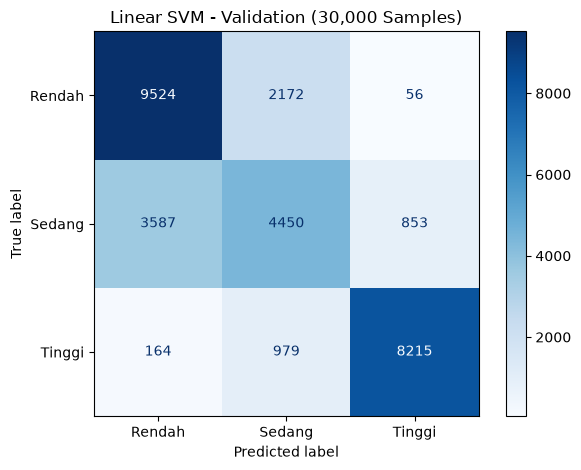

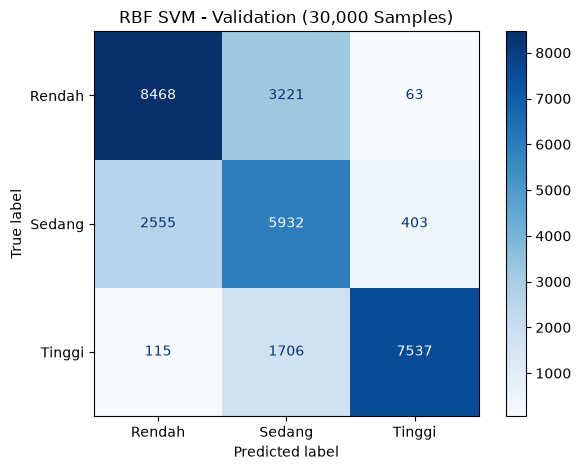

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Prediksi Linear SVM pada validation subset yang sama dengan RBF
y_pred_linear_same = linear_model.predict(X_val_rbf)

# Confusion Matrix Linear SVM
cm_linear = confusion_matrix(y_val_rbf, y_pred_linear_same)

ConfusionMatrixDisplay(
    confusion_matrix=cm_linear,
    display_labels=linear_model.classes_
).plot(cmap="Blues", values_format="d")

plt.title("Linear SVM - Validation (30,000 Samples)")
plt.tight_layout()
plt.show()


# Confusion Matrix RBF SVM
cm_rbf = confusion_matrix(y_val_rbf, y_pred_rbf)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rbf,
    display_labels=rbf_model.classes_
).plot(cmap="Blues", values_format="d")

plt.title("RBF SVM - Validation (30,000 Samples)")
plt.tight_layout()
plt.show()

In [27]:
# Save experiment results

from pathlib import Path

output_dir = Path("../out/svm")
output_dir.mkdir(parents=True, exist_ok=True)

# Save comparison metrics
comparison_df.to_csv(
    output_dir / "svm_model_comparison.csv",
    index=False
)

# Save confusion matrices
pd.DataFrame(
    cm_linear,
    index=linear_model.classes_,
    columns=linear_model.classes_
).to_csv(output_dir / "linear_svm_confusion_matrix.csv")

pd.DataFrame(
    cm_rbf,
    index=rbf_model.classes_,
    columns=rbf_model.classes_
).to_csv(output_dir / "rbf_svm_confusion_matrix.csv")

print("All SVM results saved!")
print("Output directory:", output_dir.resolve())

All SVM results saved!
Output directory: C:\IF SEM 5\Data Science Teori\Cooked-DS-Final-Project\out\svm


**Dokumentasi:** Cell diagnostik lama untuk memeriksa variabel. Tidak diperlukan dalam workflow final; gunakan cell validasi pada bagian tambahan di akhir notebook.


In [21]:
print("=== DF ===")
print(df.shape)
print("demand_level in df:", "demand_level" in df.columns)

print("\n=== TRAIN_DF ===")
print(train_df.shape)
print("demand_level in train_df:", "demand_level" in train_df.columns)
print(train_df.columns.tolist())

print("\n=== LINEAR TRAIN ===")
print(linear_train.shape)
print("demand_level in linear_train:", "demand_level" in linear_train.columns)
print(linear_train.columns.tolist())

print("\n=== RBF TRAIN ===")
print(rbf_train.shape)
print("demand_level in rbf_train:", "demand_level" in rbf_train.columns)
print(rbf_train.columns.tolist())

=== DF ===
(1053841, 22)
demand_level in df: True

=== TRAIN_DF ===
(668809, 22)
demand_level in train_df: True
['hour', 'zone_id', 'PU_longitude', 'PU_latitude', 'PU_zone_name', 'PU_borough', 'is_airport', 'is_cbd', 'hour_of_day', 'day_of_week', 'month', 'is_weekend', 'is_holiday', 'is_major_nyc_event', 'lag_1', 'lag_24', 'lag_168', 'roll_24', 'roll_168', 'target_pickup_count', 'demand_level', 'split']

=== LINEAR TRAIN ===
(150000, 22)
demand_level in linear_train: True
['hour', 'zone_id', 'PU_longitude', 'PU_latitude', 'PU_zone_name', 'PU_borough', 'is_airport', 'is_cbd', 'hour_of_day', 'day_of_week', 'month', 'is_weekend', 'is_holiday', 'is_major_nyc_event', 'lag_1', 'lag_24', 'lag_168', 'roll_24', 'roll_168', 'target_pickup_count', 'demand_level', 'split']

=== RBF TRAIN ===
(15000, 22)
demand_level in rbf_train: True
['hour', 'zone_id', 'PU_longitude', 'PU_latitude', 'PU_zone_name', 'PU_borough', 'is_airport', 'is_cbd', 'hour_of_day', 'day_of_week', 'month', 'is_weekend', 'is_hol

# Workflow final yang disarankan (jalankan cell secara berurutan)

Bagian ini disediakan sebagai workflow ringkas dan aman untuk menjalankan eksperimen tanpa `Run All` pada cell lama. Cell-code asli di atas dipertahankan. Jalankan cell di bagian ini satu per satu. Linear SVM dijalankan terlebih dahulu; RBF memakai sampel lebih kecil dan subset Validation agar komputasi lebih terkendali. Test tetap tidak digunakan.


## A. Import, konfigurasi, dan load data

Memuat package, menentukan 15 fitur yang sesuai schema dataset, mencari file Parquet dari beberapa path, lalu membentuk Train dan Validation. Jika kernel baru, mulai dari cell ini.

In [ ]:
from pathlib import Path
import time
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

FEATURES = [
    'hour_of_day', 'day_of_week', 'month', 'is_weekend', 'is_holiday',
    'is_major_nyc_event', 'PU_longitude', 'PU_latitude', 'is_airport', 'is_cbd',
    'lag_1', 'lag_24', 'lag_168', 'roll_24', 'roll_168'
]
TARGET = 'demand_level'
SEED = 42
path_options = [Path('../datasets/interim/2026/features_dataset.parquet'), Path('datasets/interim/2026/features_dataset.parquet'), Path('../../datasets/interim/2026/features_dataset.parquet')]
DATA_PATH = next((p for p in path_options if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('features_dataset.parquet tidak ditemukan. Periksa lokasi dataset.')
df = pd.read_parquet(DATA_PATH)
missing_cols = [c for c in FEATURES + [TARGET, 'split'] if c not in df.columns]
if missing_cols:
    raise ValueError(f'Kolom yang dibutuhkan tidak tersedia: {missing_cols}')
if df[FEATURES + [TARGET, 'split']].isna().any().any():
    raise ValueError('Ada missing value pada fitur/target/split. Periksa dataset sebelum training.')
train_df = df[df['split'] == 'train'].copy()
val_df = df[df['split'] == 'validation'].copy()
print('Dataset:', df.shape, '| Train:', train_df.shape, '| Validation:', val_df.shape)
print('Target Train:\n', train_df[TARGET].value_counts())


## B. Sampling stratified pada Train

Sampling menjaga proporsi kelas. Linear SVM menggunakan maksimum 50.000 sampel per kelas (maksimum 150.000 total); RBF menggunakan maksimum 5.000 per kelas (maksimum 15.000 total) untuk menekan waktu training. Sampling hanya dilakukan pada Train.

In [ ]:
linear_parts = [g.sample(n=min(len(g), 50000), random_state=SEED) for _, g in train_df.groupby(TARGET)]
rbf_parts = [g.sample(n=min(len(g), 5000), random_state=SEED) for _, g in train_df.groupby(TARGET)]
linear_sample = pd.concat(linear_parts, ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
rbf_sample = pd.concat(rbf_parts, ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
X_linear, y_linear = linear_sample[FEATURES], linear_sample[TARGET].astype(str)
X_rbf, y_rbf = rbf_sample[FEATURES], rbf_sample[TARGET].astype(str)
X_val, y_val = val_df[FEATURES], val_df[TARGET].astype(str)
print('Linear sample:', X_linear.shape, y_linear.value_counts().to_dict())
print('RBF sample:', X_rbf.shape, y_rbf.value_counts().to_dict())
print('Validation full rows:', len(X_val))


## C. Helper evaluasi

Fungsi ini fit pipeline (scaler + model), mengukur waktu training dan prediction, serta menghitung metrik Validation. Macro metrics merata-ratakan performa antar kelas.

In [ ]:
def evaluate_svm(name, pipeline, Xtr, ytr, Xva, yva):
    start = time.perf_counter()
    pipeline.fit(Xtr, ytr)
    train_seconds = time.perf_counter() - start
    start = time.perf_counter()
    pred = pipeline.predict(Xva)
    predict_seconds = time.perf_counter() - start
    metrics = {
        'model': name,
        'accuracy': accuracy_score(yva, pred),
        'precision_macro': precision_score(yva, pred, average='macro', zero_division=0),
        'recall_macro': recall_score(yva, pred, average='macro', zero_division=0),
        'f1_macro': f1_score(yva, pred, average='macro', zero_division=0),
        'train_seconds': train_seconds,
        'predict_seconds': predict_seconds,
        'n_train': len(Xtr),
        'n_validation': len(Xva)
    }
    print(f'{name} selesai. Train: {train_seconds:.2f}s | Predict: {predict_seconds:.2f}s')
    print(classification_report(yva, pred, zero_division=0))
    return metrics, pred, pipeline


## D. Training dan evaluasi Linear SVM

Linear SVM adalah model prioritas. `StandardScaler` dipasang di dalam Pipeline sehingga scaling dipelajari dari Train sample saja. Validation menggunakan seluruh baris Validation.

In [ ]:
linear_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', LinearSVC(class_weight='balanced', max_iter=5000, random_state=SEED))
])
linear_metrics_final, linear_pred_final, linear_model_final = evaluate_svm(
    'Linear SVM', linear_pipeline, X_linear, y_linear, X_val, y_val
)
print('Linear metrics:', linear_metrics_final)
cm = confusion_matrix(y_val, linear_pred_final, labels=['Rendah', 'Sedang', 'Tinggi'])
ConfusionMatrixDisplay(cm, display_labels=['Rendah', 'Sedang', 'Tinggi']).plot(values_format='d')
plt.title('Linear SVM - Validation Confusion Matrix')
plt.tight_layout()
plt.show()


## E. RBF SVM versi lebih ringan (opsional)

Jalankan setelah Linear selesai dan hanya jika waktu/hardware memungkinkan. RBF dibatasi 15.000 sampel Train dan 30.000 Validation sample stratified. Hasilnya harus dilabeli sebagai evaluasi pada subset Validation, bukan seluruh Validation.

In [ ]:
# Subset validation secara stratified agar prediksi kernel tidak terlalu berat
X_val_rbf, _, y_val_rbf, _ = train_test_split(
    X_val, y_val, train_size=min(30000, len(X_val)), random_state=SEED, stratify=y_val
)
rbf_pipeline_final = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', class_weight='balanced'))
])
rbf_metrics_final, rbf_pred_final, rbf_model_final = evaluate_svm(
    'RBF SVM (subset)', rbf_pipeline_final, X_rbf, y_rbf, X_val_rbf, y_val_rbf
)
cm_rbf_final = confusion_matrix(y_val_rbf, rbf_pred_final, labels=['Rendah', 'Sedang', 'Tinggi'])
ConfusionMatrixDisplay(cm_rbf_final, display_labels=['Rendah', 'Sedang', 'Tinggi']).plot(values_format='d')
plt.title('RBF SVM - Validation Subset Confusion Matrix')
plt.tight_layout()
plt.show()


## F. Bandingkan dan simpan metrik

Cell ini menyimpan model yang berhasil dijalankan saja. Jika RBF tidak dijalankan atau dihentikan, tabel tetap dapat dibuat menggunakan Linear SVM.

In [ ]:
results = [linear_metrics_final]
if 'rbf_metrics_final' in globals():
    results.append(rbf_metrics_final)
metrics_final_df = pd.DataFrame(results).sort_values('f1_macro', ascending=False)
display(metrics_final_df)
out_candidates = [Path('../out'), Path('out'), Path('../../out')]
OUT_DIR = next((p for p in out_candidates if p.exists()), out_candidates[0])
OUT_DIR.mkdir(parents=True, exist_ok=True)
metrics_final_df.to_csv(OUT_DIR / 'svm_validation_metrics_final.csv', index=False)
print('Saved:', (OUT_DIR / 'svm_validation_metrics_final.csv').resolve())


## G. Catatan eksperimen

- Validation dipakai untuk membandingkan model; Test belum digunakan.
- Sampling membatasi jumlah data training, sehingga hasil merupakan performa model yang dilatih menggunakan subset Train.
- RBF di workflow ini menggunakan subset Validation karena biaya prediksi kernel dapat tinggi.
- Jangan menyatakan RBF lebih baik/lebih buruk sebelum metriknya benar-benar dihasilkan.
- Jalankan cell secara selektif; jangan `Run All` pada notebook ini karena cell eksperimen lama masih dipertahankan dan dapat menjalankan RBF dengan konfigurasi lebih berat.


In [17]:
# DIAGNOSIS TARGET COLUMN

print("=== DF ===")
print("df exists:", "df" in globals())

if "df" in globals():
    print("df shape:", df.shape)
    print("df columns:")
    print(df.columns.tolist())

print("\n=== TRAIN DF ===")
print("train_df exists:", "train_df" in globals())

if "train_df" in globals():
    print("train_df shape:", train_df.shape)
    print("train_df columns:")
    print(train_df.columns.tolist())

print("\n=== TARGET CHECK ===")
for name in ["df", "train_df", "val_df", "X_train", "y_train"]:
    if name in globals():
        obj = globals()[name]
        if hasattr(obj, "columns"):
            print(f"{name}: demand_level =", "demand_level" in obj.columns)
        elif hasattr(obj, "name"):
            print(f"{name}: name =", obj.name)

=== DF ===
df exists: True
df shape: (1053841, 22)
df columns:
['hour', 'zone_id', 'PU_longitude', 'PU_latitude', 'PU_zone_name', 'PU_borough', 'is_airport', 'is_cbd', 'hour_of_day', 'day_of_week', 'month', 'is_weekend', 'is_holiday', 'is_major_nyc_event', 'lag_1', 'lag_24', 'lag_168', 'roll_24', 'roll_168', 'target_pickup_count', 'demand_level', 'split']

=== TRAIN DF ===
train_df exists: True
train_df shape: (668809, 22)
train_df columns:
['hour', 'zone_id', 'PU_longitude', 'PU_latitude', 'PU_zone_name', 'PU_borough', 'is_airport', 'is_cbd', 'hour_of_day', 'day_of_week', 'month', 'is_weekend', 'is_holiday', 'is_major_nyc_event', 'lag_1', 'lag_24', 'lag_168', 'roll_24', 'roll_168', 'target_pickup_count', 'demand_level', 'split']

=== TARGET CHECK ===
df: demand_level = True
train_df: demand_level = True
val_df: demand_level = True
